# NUTDTS 816 Time Series Analysis
## Lab 0: Familiarisation (26 August 2026)

Goals: confirm Colab works, load a series with a DatetimeIndex, make a plot, save the notebook to your GitHub repository.

1. File > Save a copy in Drive.
2. Run the setup cell.
3. Run the data cell and the plot cell; change the plot to the log scale and run again.
4. Create a public GitHub repository named `nutdts816-<surname>`; File > Save a copy in GitHub.

In [4]:
# ---- Setup: run once per Colab session ----
# 1. Install the course libraries (about two minutes the first time)
!pip install -q statsmodels pmdarima statsforecast neuralforecast lightgbm arch plotly

# 2. Fetch the course data module and data snapshots from the course repository.
#    Replace REPO with your fork or the official course repository URL.
REPO = "https://raw.githubusercontent.com/Favour-Fregene/NUTDTS816_Course_Repository/main"
import urllib.request, os
os.makedirs("data", exist_ok=True)
urllib.request.urlretrieve(f"{REPO}/src/tsdata.py", "tsdata.py")
DATA_FILES = ["nigeria_cpi", "nigeria_fx", "nigeria_grid", "nigeria_malaria", "nigeria_rainfall", "bonny_light", "daily_demand",
              "airpassengers", "a10", "h02", "ausbeer", "elecequip", "usmelec", "goog", "nile", "austourists", "oil", "dax", "uschange", "elecdemand"]
for f in DATA_FILES:
    urllib.request.urlretrieve(f"{REPO}/data/{f}.csv", f"data/{f}.csv")

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
import tsdata
print("Setup complete.")

Setup complete.


In [5]:
ap = tsdata.airpassengers()
print(type(ap), ap.index.freq)
ap.head()

<class 'pandas.core.series.Series'> <MonthBegin>


,passengers
date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


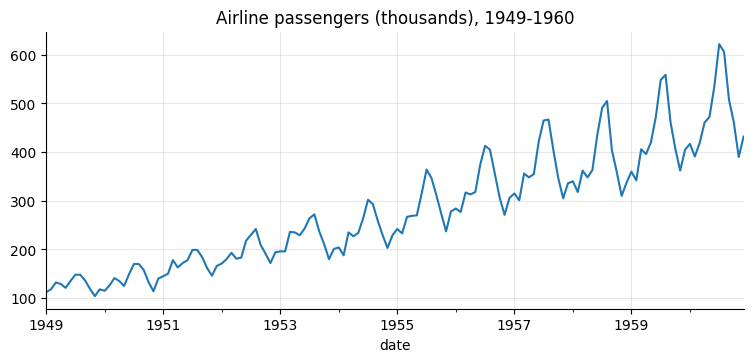

In [6]:
ax = ap.plot(title='Airline passengers (thousands), 1949-1960')
# Change to np.log(ap).plot(...) and run again

In [7]:
cpi = tsdata.nigeria_cpi(); fx = tsdata.nigeria_fx(); grid = tsdata.nigeria_grid()
pd.concat([cpi, fx, grid], axis=1).tail()

,cpi,ngn_usd,generation_mw
date,,,
2026-03-01,NaN,1378.8184,3642.5
2026-04-01,NaN,1360.7185,3500.0
2026-05-01,NaN,1369.4947,NaN
2026-06-01,NaN,1366.4902,NaN
2026-07-01,NaN,1372.7523,NaN


## Self-check (ungraded)

1. What is the seasonal period m of monthly CPI? Of daily electricity demand?
2. Write one sentence on what the CPI plot shows after mid-2023.
3. In your own words: why can you not use random k-fold cross-validation on a time series?

In [9]:
#Q1
print(type(cpi), cpi.index.freq)
print()
daily_demand = tsdata.daily_demand()
print(type(daily_demand), daily_demand.index.freq)

<class 'pandas.core.series.Series'> <MonthBegin>

<class 'pandas.core.series.Series'> <Day>


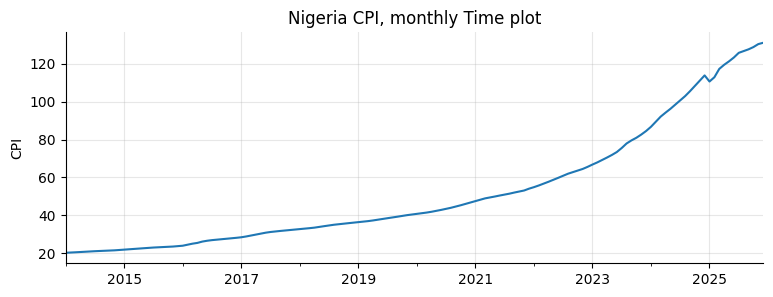

In [18]:
#Q2
# Time Plot for both Series
fig, ax = plt.subplots(figsize=(9, 3))
cpi.plot(ax=ax, title='Nigeria CPI, monthly Time plot', ylabel='CPI', xlabel='')
plt.show()

in 2023 there was a rapid growth in the chat

Q3 It's because random k-fold cross-validation shuffles data into random train/test splits, and that breaks the one thing time series data depends on: order.